In [1]:
import pandas as pd
import json
import numpy as np
import os


def get_json(json_file, dataset_key):
    """
    loading dockq & rs from neogary's json file
    """
    json_data = json.load(open(json_file, "r"))
    pdbs = list(json_data.keys())
    data = []
    for pdb in pdbs:
        for method in json_data[pdb].keys():
            if method == "inputs_info":
                continue
            for cif_path, cif_data in json_data[pdb][method].items():
                seq_num = cif_data["inputs_info"]["seq_num"] if "inputs_info" in cif_data else -1
                basename = os.path.basename(cif_path)
                iface_id = (
                    -1
                    if ("cluster" not in cif_path or "chai" in cif_path)
                    else int(basename.split("_")[0].split("-")[-1])
                )
                cluster_id = int(cif_data["cluster_id"]) if "cluster_id" in cif_data else -1
                seed = cif_data["seed"]
                sample_id = cif_data["sample_id"]
                idockq = np.mean(cif_data["idockq"])
                ilddt = np.mean(cif_data["ilddt"])
                if dataset_key in ["vali_PP", "fb_PP"]:
                    idockq = np.mean(cif_data["dockq"])
                    ilddt = np.mean(cif_data["lddt"])
                ranking_score = cif_data["ranking_score"]
                data.append(
                    {
                        "cif_path": cif_path,
                        "method": method,
                        "pdb": pdb,
                        "idockq": idockq,
                        "ilddt": ilddt,
                        "ranking_score": ranking_score,
                        "seed": seed,
                        "sample_id": sample_id,
                        "iface_id": iface_id,
                        "cluster_id": cluster_id,
                        "seq_num": seq_num,
                    }
                )

    df = pd.DataFrame(data)
    return df


datasets = ["vali_AA", "vali_PP", "vali_dsDNA", "fb_AA", "fb_PP", "fb_dsDNA", "casp"]
df_dict = {}
for dataset in datasets:
    df = get_json(f"./json/{dataset}.json", dataset_key=dataset)
    df["dataset"] = dataset
    df_dict[dataset] = df
    print(dataset, df["method"].unique())

# create temp folder
os.makedirs("./df", exist_ok=True)
os.makedirs("./figs", exist_ok=True)

vali_AA <ArrowStringArray>
['base_constraint_nc', 'base_constraint_gt',          'ab_random',
              'ab_NE',       'ab_distogram',    'ab_NE_distogram',
   'vali_AA_1_manual',   'vali_AA_2_manual',   'vali_AA_3_manual',
   'vali_AA_4_manual',   'vali_AA_5_manual',   'vali_AA_6_manual',
   'vali_AA_7_manual',   'vali_AA_8_manual',   'vali_AA_9_manual']
Length: 15, dtype: str


/root/conda/envs/dyna/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/root/conda/envs/dyna/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


vali_PP <ArrowStringArray>
[      'pxm_protenix', 'base_constraint_nc',          'ab_random',
              'ab_NE',       'ab_distogram',    'ab_NE_distogram',
          'vali_PP_6', 'base_constraint_gt']
Length: 8, dtype: str
vali_dsDNA <ArrowStringArray>
[        'base_nc',        '55199_nc',        '55199_gt',        '55199_at',
   'vali_dsDNA_05',    'vali_dsDNA_1',   'vali_dsDNA_15',    'vali_dsDNA_2',
   'vali_dsDNA_25',    'vali_dsDNA_3',   'vali_dsDNA_35',    'vali_dsDNA_4',
   'vali_dsDNA_45',    'vali_dsDNA_5',   'vali_dsDNA_55',    'vali_dsDNA_6',
   'vali_dsDNA_65',    'vali_dsDNA_7',   'vali_dsDNA_75',    'vali_dsDNA_8',
   'vali_dsDNA_85',    'vali_dsDNA_9',       'ab_random',           'ab_NE',
    'ab_distogram', 'ab_NE_distogram']
Length: 26, dtype: str
fb_AA <ArrowStringArray>
[             'Protenix_base_nc',   'Protenix_base_constraint_nc',
 'base_constraint_manual_tau_06', 'base_constraint_manual_tau_09',
                        'chai-1',               'chai-const

/root/conda/envs/dyna/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/root/conda/envs/dyna/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


fb_PP <ArrowStringArray>
[           'Protenix_base_nc', 'Protenix_base_constraint_nc',
          'base_constraint_at',                      'chai-1',
                     'boltz-1',             'chai-constraint']
Length: 6, dtype: str


/root/conda/envs/dyna/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/root/conda/envs/dyna/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


fb_dsDNA <ArrowStringArray>
[                     'chai-1',             'chai-constraint',
                     'boltz-1',            'Protenix_base_nc',
 'Protenix_base_constraint_nc',                    '55199_at']
Length: 6, dtype: str
casp <ArrowStringArray>
[       'base_constraint_manual',                       'base_nc',
            'base_constraint_nc',                        'chai-1',
               'chai-constraint',                       'boltz-1',
 'base_constraint_manual_tau_08',         'casp15_t06_casp16_t08']
Length: 8, dtype: str


In [2]:
import pandas as pd

datasets = ["vali_AA", "vali_PP", "vali_dsDNA", "fb_AA", "fb_PP", "fb_dsDNA", "casp"]
dfs = []
for dataset in datasets:
    print(dataset, end=",")
    df = df_dict[dataset].copy()
    df["dataset"] = dataset
    # preprocess
    # num_ifaces
    if "vali" in dataset:
        df = df[df["iface_id"] < 11]
    else:
        df = df[df["iface_id"] < 6]  # take only font 5
    df.loc[:, "idockq"] = df["idockq"].fillna(0.0)
    df.loc[:, "ilddt"] = df["ilddt"].fillna(0.0)
    ####
    if dataset == "vali_AA":
        df = df[
            df["method"].isin(
                [
                    "base_constraint_nc",
                    "base_constraint_gt",
                    "vali_AA_8_manual",
                    "ab_random",
                    "ab_NE",
                    "ab_NE_distogram",
                ]
            )
        ]
    if dataset == "vali_PP":
        df = df[
            df["method"].isin(
                [
                    "base_constraint_nc",
                    "base_constraint_gt",
                    "vali_PP_6",
                    "ab_random",
                    "ab_NE",
                    "ab_NE_distogram",
                ]
            )
        ]
    if dataset == "vali_dsDNA":
        df = df[
            df["method"].isin(
                [
                    "55199_nc",
                    "55199_gt",
                    "vali_dsDNA_5",
                    "ab_random",
                    "ab_NE",
                    "ab_NE_distogram",
                ]
            )
        ]
    if dataset == "fb_AA":
        df = df[
            df["method"].isin(
                [
                    "base_constraint_manual_tau_08",
                    "Protenix_base_nc",
                    "chai-1",
                    "chai-constraint",
                    "boltz-1",
                    "Protenix_base_constraint_nc",
                ]
            )
        ]
    if dataset == "fb_PP":
        df = df[~((df["method"] == "chai-1") & (df["sample_id"] > 4))]
    if dataset == "casp":
        df = df[
            df["method"].isin(
                [
                    "base_nc",
                    "chai-1",
                    "chai-constraint",
                    "boltz-1",
                    "casp15_t06_casp16_t08",
                    "base_constraint_nc",
                ]
            )
        ]
        df["method"] = df["method"].map(lambda x: "Protenix_base_constraint_nc" if x == "base_constraint_nc" else x)
        df = df[~((df["method"] == "chai-constraint") & (df["sample_id"] > 4))]
        df = df[~((df["method"] == "Protenix_base_constraint_nc") & (df["sample_id"] > 24))]
        #
        df["dataset"] = "CASP 15/16\nNum Of Seed: 100"
        dfs.append(df.copy())
        df["dataset"] = "CASP 15/16"

    # dataset seed is from 101~105
    df = df[df["seed"] < 106]
    dfs.append(df)
print("dataset loaded")
df = pd.concat(dfs)
df = df.astype({"idockq": float, "ranking_score": float, "seed": int})
# display n_cif
for dataset, subset in df.groupby("dataset"):
    for method, method_df in subset.groupby("method"):
        print(f"dataset:{dataset}, method:{method}, n_cif:{len(method_df)}, n_seeds:{method_df['seed'].nunique()}")
    print("=" * 100)
# method postprocesing
METHOD_NAME_MAPPING = {
    "base_constraint_nc": "Base",
    "Protenix_base_constraint_nc": "Protenix (BaseConstraint)",
    "55199_nc": "Base",
    "base_constraint_gt": "Site-Oracle",
    "55199_gt": "Site-Oracle",
    "vali_AA_8_manual": "DynaHelix",
    "vali_PP_6": "DynaHelix",
    "vali_dsDNA_5": "DynaHelix",
    ####
    "55199_at": "DynaHelix",
    "base_constraint_at": "DynaHelix",
    "base_constraint_manual": "DynaHelix",
    "base_constraint_manual_tau_06": "DynaHelix",
    "base_constraint_manual_tau_08": "DynaHelix",
    "casp15_t06_casp16_t08": "DynaHelix",
    "base_constraint_manual_selected_tau": "DynaHelix",
    "chai-1": "Chai-1",
    "boltz-1": "Boltz-1",
    "Protenix_base_nc": "Protenix",
    "base_nc": "Protenix",
    "chai-constraint": "Chai-1 (DynaHelix)",
    # Ablation study
    "ab_random": "RandomHotSpots",
    "ab_NE": "WithoutExpansion",
    "ab_NE_distogram": "TopContacts",
}
df["method"] = df["method"].map(METHOD_NAME_MAPPING).fillna(df["method"])
##
df

vali_AA,vali_PP,vali_dsDNA,fb_AA,fb_PP,fb_dsDNA,casp,dataset loaded
dataset:CASP 15/16, method:Protenix_base_constraint_nc, n_cif:2125, n_seeds:5
dataset:CASP 15/16, method:base_nc, n_cif:2125, n_seeds:5
dataset:CASP 15/16, method:boltz-1, n_cif:2125, n_seeds:5
dataset:CASP 15/16, method:casp15_t06_casp16_t08, n_cif:2120, n_seeds:5
dataset:CASP 15/16, method:chai-1, n_cif:2125, n_seeds:5
dataset:CASP 15/16, method:chai-constraint, n_cif:2015, n_seeds:5
dataset:CASP 15/16
Num Of Seed: 100, method:Protenix_base_constraint_nc, n_cif:42500, n_seeds:100
dataset:CASP 15/16
Num Of Seed: 100, method:base_nc, n_cif:42450, n_seeds:100
dataset:CASP 15/16
Num Of Seed: 100, method:boltz-1, n_cif:42500, n_seeds:100
dataset:CASP 15/16
Num Of Seed: 100, method:casp15_t06_casp16_t08, n_cif:42425, n_seeds:100
dataset:CASP 15/16
Num Of Seed: 100, method:chai-1, n_cif:42500, n_seeds:100
dataset:CASP 15/16
Num Of Seed: 100, method:chai-constraint, n_cif:40105, n_seeds:100
dataset:fb_AA, method:Protenix_bas

,cif_path,method,pdb,idockq,ilddt,ranking_score,seed,sample_id,iface_id,cluster_id,seq_num,dataset
0,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,Base,7um3,0.135873,0.186489,0.863540,102,41,-1,-1,-1,vali_AA
1,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,Base,7um3,0.139026,0.188977,0.868113,102,0,-1,-1,-1,vali_AA
2,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,Base,7um3,0.108501,0.160694,0.865059,102,30,-1,-1,-1,vali_AA
3,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,Base,7um3,0.189019,0.265425,0.866542,102,15,-1,-1,-1,vali_AA
4,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,Base,7um3,0.112277,0.170462,0.863496,102,42,-1,-1,-1,vali_AA
...,...,...,...,...,...,...,...,...,...,...,...,...
543130,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,H1232,0.139278,0.236650,0.419676,104,4,5,5,-1,CASP 15/16
543131,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,H1232,0.140652,0.199012,0.429311,104,3,5,5,-1,CASP 15/16
543132,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,H1232,0.135315,0.195313,0.458912,104,0,5,5,-1,CASP 15/16
543133,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,H1232,0.235983,0.247250,0.437702,104,1,5,5,-1,CASP 15/16


In [3]:
new_df = df[(df["method"] == "Chai-1 (DynaHelix)") & (df["dataset"] == "CASP 15/16")]
new_df["pdb"].unique()
# new_df[new_df['pdb'] == 'H1232']
print(df.columns)
print(df["dataset"].unique())
print(df["method"].unique())
###
new_df = df[df["dataset"] == "vali_PP"]
# new_df[(new_df['pdb'] == '7t5p') & (new_df['method'] == 'RandomHotSpots')]
new_df[(new_df["pdb"] == "7t5p") & (new_df["method"] == "DynaHelix")]

Index(['cif_path', 'method', 'pdb', 'idockq', 'ilddt', 'ranking_score', 'seed',
       'sample_id', 'iface_id', 'cluster_id', 'seq_num', 'dataset'],
      dtype='str')
<ArrowStringArray>
[                     'vali_AA',                      'vali_PP',
                   'vali_dsDNA',                        'fb_AA',
                        'fb_PP',                     'fb_dsDNA',
 'CASP 15/16\nNum Of Seed: 100',                   'CASP 15/16']
Length: 8, dtype: str
<ArrowStringArray>
[                     'Base',               'Site-Oracle',
            'RandomHotSpots',          'WithoutExpansion',
               'TopContacts',                 'DynaHelix',
                  'Protenix', 'Protenix (BaseConstraint)',
                    'Chai-1',        'Chai-1 (DynaHelix)',
                   'Boltz-1']
Length: 11, dtype: str


,cif_path,method,pdb,idockq,ilddt,ranking_score,seed,sample_id,iface_id,cluster_id,seq_num,dataset
6000,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.659898,0.593338,0.756036,102,0,4,4,-1,vali_PP
6001,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.601933,0.612027,0.749693,102,4,4,4,-1,vali_PP
6002,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.593698,0.608182,0.750698,102,2,4,4,-1,vali_PP
6003,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.603295,0.605161,0.750179,102,3,4,4,-1,vali_PP
6004,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.634898,0.620697,0.751882,102,1,4,4,-1,vali_PP
...,...,...,...,...,...,...,...,...,...,...,...,...
6245,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.698184,0.653674,0.742018,104,3,6,6,-1,vali_PP
6246,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.617081,0.584323,0.735931,104,4,6,6,-1,vali_PP
6247,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.643822,0.625535,0.744815,104,0,6,6,-1,vali_PP
6248,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,DynaHelix,7t5p,0.679191,0.624421,0.742833,104,1,6,6,-1,vali_PP


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. 全局配置 (Global Config)
# ==========================================
os.makedirs("./figs", exist_ok=True)
sns.set_style("white")

FONT_CONFIG = {
    "title": 14,
    "xlabel": 13,
    "ylabel": 13,
    "xtick": 11,
    "ytick": 11,
    "bar_text": 7.5,
    "legend": 12,
}
ENABLE_HATCH = True
HATCH_EDGE_COLOR = "white"
X_ORDER = ["Oracle", "Top-5", "Top-1"]

DATASET_TITLE_MAP = {
    "vali_AA": "Validation\nAntigen-Antibody",
    "vali_PP": "Validation\nProtein-Protein",
    "vali_dsDNA": "Validation\nProtein-dsDNA",
    "fb_AA": "FoldBench\nAntigen-Antibody",
    "fb_PP": "FoldBench\nProtein-Protein",
    "fb_dsDNA": "FoldBench\nProtein-dsDNA",
    "CASP 15/16": "CASP 15/16",
    "CASP 15/16\nNum Of Seed: 100": "CASP 15/16\nNum Of Seed: 100",
}


# 1~3 圖主配色
def color_define(saturate=0.85):
    method_color_map = {
        "DynaHelix": "#ff002b",
        "DynaHelix-IfaceRanking": "#ff4d6d",
        "Base": "#FFE4A4",
        "Site-Oracle": "#ffd166",
        "Protenix": "#A6CEE3",
        "Chai-1": "#B2DF8A",
        "Boltz-1": "#cdb4db",
        # Chai-1 補充圖配色
        "Protenix (DynaHelix)": "#ff002b",
        "Protenix (DynaHelix-IfaceRanking)": "#ff4d6d",
        "Protenix (BaseConstraint)": "#ffd166",
        "Chai-1 (DynaHelix)": "#52AD03",
    }
    def rgb_to_hex(r, g, b):
        return f"#{r:02x}{g:02x}{b:02x}"
    for method, color in list(method_color_map.items()):
        color_rgb = [int(x * 255) for x in sns.desaturate(color, saturate)]
        method_color_map[method] = rgb_to_hex(color_rgb[0], color_rgb[1], color_rgb[2])
    return method_color_map


GLOBAL_COLOR_MAP = color_define()
MAIN_METHODS_ORDER = [
    "DynaHelix-IfaceRanking",
    "DynaHelix",
    "Site-Oracle",
    "Base",
    "Protenix",
    "Chai-1",
    "Boltz-1",
]

MAIN_GRID = [
    ["vali_AA", "vali_PP", "vali_dsDNA"],
    ["fb_AA", "fb_PP", "fb_dsDNA"],
    ["CASP 15/16", "CASP 15/16\nNum Of Seed: 100", "CASP 15/16"],
]


# ==========================================
# 2. 核心計算函數
# ==========================================
def calculate_metrics(raw_df, score_col, score_name, method_mapping=None):
    df = raw_df.dropna(subset=[score_col, "ranking_score"]).copy()
    if method_mapping:
        df["method"] = df["method"].map(lambda x: method_mapping.get(x, x))

    df["score"] = df[score_col]
    df["score_name"] = score_name

    results = []
    grouped = df.groupby(["dataset", "method", "pdb"])

    for (dataset, method, pdb), group in grouped:
        sorted_group = group.sort_values("ranking_score", ascending=False)
        if sorted_group.empty:
            continue
        s_name = sorted_group.iloc[0]["score_name"]

        top1_val = sorted_group.iloc[0]["score"]
        top5_val = sorted_group.iloc[:5]["score"].max()

        if "cluster_id" in sorted_group.columns and sorted_group.iloc[0]["cluster_id"] != -1:
            cluster_top5_val = sorted_group.groupby("cluster_id").head(1).iloc[:5]["score"].max()
            iface_name = method if method.endswith("-IfaceRanking") else f"{method}-IfaceRanking"
            results.append([dataset, iface_name, pdb, "Top-5", cluster_top5_val, s_name])

        best_val = sorted_group["score"].max()

        results.append([dataset, method, pdb, "Top-1", top1_val, s_name])
        results.append([dataset, method, pdb, "Top-5", top5_val, s_name])
        results.append([dataset, method, pdb, "Oracle", best_val, s_name])

    if not results:
        raise ValueError(f"❌ 計算後結果為空！請檢查欄位 '{score_col}' 是否存在。")

    res_df = pd.DataFrame(results, columns=["Dataset", "Method", "PDB", "Metric", "Score", "ScoreName"])

    filtered_results = []
    dataset_pdb_counts = {}

    print(f"\n--- [{score_name}] 各 Dataset 共有 PDB 數量統計 ---")
    for dataset in res_df["Dataset"].unique():
        ds_df = res_df[res_df["Dataset"] == dataset]
        methods = ds_df["Method"].unique()

        pdb_sets = [set(ds_df[ds_df["Method"] == m]["PDB"]) for m in methods]
        valid_pdb_sets = [s for s in pdb_sets if len(s) > 0]

        common_pdbs = set.intersection(*valid_pdb_sets) if valid_pdb_sets else set()

        ds_filtered = ds_df[ds_df["PDB"].isin(common_pdbs)]
        filtered_results.append(ds_filtered)
        dataset_pdb_counts[dataset] = len(common_pdbs)
        print(f"Dataset: {dataset:<25} | Common PDB Count: {len(common_pdbs)}")
    print("--------------------------------------------------")

    plot_df = pd.concat(filtered_results, ignore_index=True)
    return plot_df, dataset_pdb_counts


# ==========================================
# 3. 通用網格繪圖函數 (支持 3x3, 2x3 等任意結構)
# ==========================================
def plot_oracle_curve(
    raw_df,
    ax,
    selected_methods,
    method_color_map,
    score_col,
    metric_name,
    num_seeds=100,
    method_mapping=None,
):
    if raw_df.empty:
        return ax
    target_df = raw_df.copy()
    if method_mapping:
        target_df["method"] = target_df["method"].map(lambda x: method_mapping.get(x, x))

    casp_df = target_df[target_df["dataset"].astype(str).str.contains("CASP", case=False, na=False)].copy()
    if casp_df.empty:
        casp_df = target_df.copy()

    casp_df["seed_numeric"] = pd.to_numeric(casp_df["seed"], errors="coerce")
    df_unique_seed = casp_df.groupby(["method", "pdb", "seed_numeric"])[score_col].max().reset_index()
    df_unique_seed = df_unique_seed[df_unique_seed["method"].isin(selected_methods)].sort_values(
        by=["method", "pdb", "seed_numeric"]
    )

    df_unique_seed["sample_rank"] = df_unique_seed.groupby(["method", "pdb"]).cumcount() + 1
    df_unique_seed = df_unique_seed[df_unique_seed["sample_rank"] <= num_seeds]
    df_unique_seed["oracle_score"] = df_unique_seed.groupby(["method", "pdb"])[score_col].cummax()
    plot_data = df_unique_seed.groupby(["method", "sample_rank"])["oracle_score"].mean().reset_index()

    marker_list = ["o", "s", "D", "v", "p", "*", "h", "8"]
    custom_ticks = [1] + list(range(10, num_seeds + 1, 10))
    methods = [m for m in selected_methods if m in plot_data["method"].unique()]

    for i, method in enumerate(methods):
        subset = plot_data[plot_data["method"] == method].sort_values("sample_rank")
        if subset.empty:
            continue
        color = method_color_map.get(method, plt.cm.tab10(i % 10))
        marker = marker_list[i % len(marker_list)]
        marker_subset = subset[subset["sample_rank"].isin(custom_ticks)]

        ax.plot(
            subset["sample_rank"],
            subset["oracle_score"],
            label=method,
            color=color,
            linewidth=2,
            alpha=0.9,
            zorder=2,
        )
        ax.scatter(
            marker_subset["sample_rank"],
            marker_subset["oracle_score"],
            color=color,
            marker=marker,
            s=125,
            edgecolor="white",
            linewidth=0.8,
            zorder=3,
        )

    n_count = len(casp_df["pdb"].unique()) if "pdb" in casp_df.columns else 17
    ax.set_title(f"CASP 15/16\n$n = {n_count}$", fontsize=FONT_CONFIG["title"], pad=10)
    ax.set_xlabel("Number of Seeds", fontsize=FONT_CONFIG["xlabel"])
    ax.set_ylabel(f"{metric_name} (Oracle)", fontsize=FONT_CONFIG["ylabel"])
    ax.set_xticks(custom_ticks)
    ax.grid(True, axis="both", linestyle="--", alpha=0.7, linewidth=0.5)
    return ax


def draw_grid_barplot(
    plot_df,
    dataset_pdb_counts,
    raw_df,
    score_col,
    metric_name,
    layout_grid=MAIN_GRID,
    master_hue_order=MAIN_METHODS_ORDER,
    color_map=GLOBAL_COLOR_MAP,
    method_mapping=None,
    line_plot_pos=(2, 2),
    selected_line_methods=None,
    save_path="./figs/fig4_grid.pdf",
):
    if selected_line_methods is None:
        selected_line_methods = ["Boltz-1", "Chai-1", "DynaHelix", "Protenix", "Base"]

    n_rows = len(layout_grid)
    n_cols = max(len(row) for row in layout_grid)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.8 * n_cols, 4.6 * n_rows), dpi=300)
    if n_rows == 1:
        axes = np.expand_dims(axes, axis=0)
    if n_cols == 1:
        axes = np.expand_dims(axes, axis=1)

    legend_handles = {}
    hatch_config = {
        "DynaHelix-IfaceRanking": "//",
        "Protenix (DynaHelix-IfaceRanking)": "//",
        "Base": "//",
    }

    for row_idx, row_datasets in enumerate(layout_grid):
        for col_idx in range(n_cols):
            ax = axes[row_idx, col_idx]

            if col_idx >= len(row_datasets):
                ax.set_visible(False)
                continue

            dataset_key = row_datasets[col_idx]

            if col_idx == 0:
                ax.text(
                    -0.1,
                    1.1,
                    chr(97 + row_idx),
                    transform=ax.transAxes,
                    fontsize=18,
                    fontweight="bold",
                    va="top",
                    ha="right",
                )

            # 折線圖位置
            if line_plot_pos is not None and (row_idx, col_idx) == line_plot_pos:
                plot_oracle_curve(
                    raw_df,
                    ax=ax,
                    selected_methods=selected_line_methods,
                    method_color_map=color_map,
                    score_col=score_col,
                    metric_name=metric_name,
                    method_mapping=method_mapping,
                )
                h, l = ax.get_legend_handles_labels()
                for handle, label in zip(h, l):
                    if label not in legend_handles:
                        legend_handles[label] = handle
            else:
                sub_df = plot_df[plot_df["Dataset"] == dataset_key].copy()
                if sub_df.empty:
                    ax.set_visible(False)
                    continue

                group_width = 0.82
                x_centers = np.arange(len(X_ORDER))
                max_bar_height = 0

                active_methods = [m for m in master_hue_order if m in sub_df["Method"].values]
                n_bars = len(active_methods)
                if n_bars == 0:
                    continue
                bar_w = group_width / n_bars

                for x_idx, metric_type in enumerate(X_ORDER):
                    start_x = x_centers[x_idx] - (group_width / 2) + (bar_w / 2)
                    metric_data = sub_df[sub_df["Metric"] == metric_type]
                    if metric_data.empty:
                        continue

                    scores_in_group = []
                    plot_bar_data = []

                    for i, method in enumerate(active_methods):
                        m_row = metric_data[metric_data["Method"] == method]
                        if m_row.empty:
                            continue

                        scores = m_row["Score"].dropna()
                        if scores.empty:
                            continue

                        mean_val = scores.mean()
                        sem_val = scores.sem() if len(scores) > 1 else 0
                        if pd.isna(sem_val):
                            sem_val = 0

                        scores_in_group.append(mean_val)
                        plot_bar_data.append(
                            {
                                "method": method,
                                "score": mean_val,
                                "err": sem_val,
                                "idx": i,
                            }
                        )

                    group_max = max(scores_in_group) if scores_in_group else 0

                    for item in plot_bar_data:
                        method, score, err, i = (
                            item["method"],
                            item["score"],
                            item["err"],
                            item["idx"],
                        )
                        max_bar_height = max(max_bar_height, score + err)
                        color = color_map.get(method, "gray")
                        current_hatch = hatch_config.get(method) if ENABLE_HATCH else None

                        bar = ax.bar(
                            start_x + (i * bar_w),
                            score,
                            width=bar_w,
                            color=color,
                            edgecolor=HATCH_EDGE_COLOR if current_hatch else "white",
                            hatch=current_hatch,
                            linewidth=0.5,
                            label=method,
                            yerr=err,
                            capsize=0,
                            error_kw={
                                "elinewidth": 1.0,
                                "ecolor": "#333333",
                                "alpha": 0.8,
                            },
                        )
                        ax.bar_label(
                            bar,
                            fmt="%.3f",
                            padding=2,
                            fontsize=FONT_CONFIG["bar_text"] if n_bars < 5 else FONT_CONFIG["bar_text"] - 1,
                            fontweight="bold" if (score >= group_max) else "normal",
                        )

                n_count = dataset_pdb_counts.get(dataset_key, len(sub_df["PDB"].unique()))
                base_title = DATASET_TITLE_MAP.get(dataset_key, dataset_key)

                if dataset_key == "CASP 15/16\nNum Of Seed: 100":
                    display_title = "CASP 15/16\nNum Of Seed: 100"
                else:
                    display_title = f"{base_title}\n$n = {n_count}$"

                ax.set_title(display_title, fontsize=FONT_CONFIG["title"], pad=10)
                ax.set_ylabel(metric_name if col_idx == 0 else "", fontsize=FONT_CONFIG["ylabel"])
                ax.set_xticks(x_centers)
                ax.set_xticklabels(X_ORDER, fontsize=FONT_CONFIG["xtick"])
                ax.tick_params(axis="y", labelsize=FONT_CONFIG["ytick"])
                ax.set_ylim(0, max_bar_height * 1.15 if max_bar_height > 0 else 1.0)

                h, l = ax.get_legend_handles_labels()
                for handle, label in zip(h, l):
                    if label not in legend_handles:
                        legend_handles[label] = handle

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.08 if n_rows > 2 else 0.10)
    final_legend_labels = [m for m in master_hue_order if m in legend_handles]
    final_legend_handles = [legend_handles[m] for m in final_legend_labels]
    fig.legend(
        final_legend_handles,
        final_legend_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=len(final_legend_labels),
        fontsize=FONT_CONFIG["legend"],
        frameon=False,
    )
    plt.savefig(save_path, format="pdf", bbox_inches="tight", dpi=300)
    plt.show()
    print(f"✅ 成功導出: {save_path}")


# ==========================================
# 4. 專門修復第 4 圖（消融實驗）的繪圖函數
# ==========================================
def draw_ablation_barplot(df, counts_map=None):
    DATASETS = ["vali_AA", "vali_PP", "vali_dsDNA"]
    DATASET_DISPLAY_MAP = {
        "vali_AA": "Validation\nAntigen-Antibody",
        "vali_PP": "Validation\nProtein-Protein",
        "vali_dsDNA": "Validation\nProtein-dsDNA",
    }

    ABLATION_COLOR_MAP = {
        "Site-Oracle": "#FFD166",  # 明亮金黃
        "DynaHelix-IfaceRanking": "#FF3355",  # 鮮艷珊瑚紅
        "DynaHelix": "#FF002B",  # 純紅
        "WithoutExpansion": "#CDB4DB",  # 柔和紫
        "RandomHotSpots": "#B2DF8A",  # 嫩綠
        "TopContacts": "#52AD03",  # 飽和深綠
        "Base": "#A6CEE3",  # 淺藍
    }

    METHOD_ORDER = [
        "Site-Oracle",
        "DynaHelix-IfaceRanking",
        "DynaHelix",
        "WithoutExpansion",
        "RandomHotSpots",
        "TopContacts",
        "Base",
    ]

    HATCH_CONFIG = {"DynaHelix-IfaceRanking": "//"}

    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), dpi=300)
    legend_handles = {}

    for i, dataset_key in enumerate(DATASETS):
        ax = axes[i]
        ax.text(
            -0.12,
            1.12,
            chr(97 + i),
            transform=ax.transAxes,
            fontsize=16,
            fontweight="bold",
            va="top",
            ha="right",
        )

        sub_df = df[df["Dataset"] == dataset_key].copy()
        if sub_df.empty:
            continue

        y_label_text = sub_df["ScoreName"].iloc[0] if "ScoreName" in sub_df.columns else "DockQ"

        group_width = 0.82
        x_centers = np.arange(len(X_ORDER))
        max_bar_height = 0

        for x_idx, metric in enumerate(X_ORDER):
            metric_data = sub_df[sub_df["Metric"] == metric]
            if metric_data.empty:
                continue

            # 按 Metric 視角動態分派柱子（解決空白 slot 問題）
            active_methods = [m for m in METHOD_ORDER if m in metric_data["Method"].values]
            n_bars = len(active_methods)
            if n_bars == 0:
                continue

            bar_w = group_width / n_bars
            start_x = x_centers[x_idx] - (group_width / 2) + (bar_w / 2)

            scores_in_group = [metric_data[metric_data["Method"] == m]["Score"].mean() for m in active_methods]
            group_max_score = max([s for s in scores_in_group if not np.isnan(s)], default=-float("inf"))

            for j, method in enumerate(active_methods):
                score_series = metric_data[metric_data["Method"] == method]["Score"]
                score = score_series.mean()
                if pd.isna(score):
                    continue

                y_err = score_series.sem()
                if pd.isna(y_err):
                    y_err = 0

                max_bar_height = max(max_bar_height, score + y_err)
                x_pos = start_x + (j * bar_w)
                color = ABLATION_COLOR_MAP.get(method, "#888888")
                hatch_style = HATCH_CONFIG.get(method, None)

                bar = ax.bar(
                    x_pos,
                    score,
                    width=bar_w,
                    color=color,
                    edgecolor="white",
                    linewidth=0.5,
                    hatch=hatch_style,
                    label=method,
                    yerr=y_err,
                    capsize=0,
                    error_kw={"elinewidth": 1.0, "ecolor": "#333333", "alpha": 0.8},
                )

                is_highest = score >= group_max_score
                ax.bar_label(
                    bar,
                    fmt="%.3f",
                    padding=2,
                    fontsize=5.5,
                    fontweight="bold" if is_highest else "normal",
                )

        base_title = DATASET_DISPLAY_MAP.get(dataset_key, dataset_key)
        n_val = counts_map.get(dataset_key, None) if counts_map else None
        full_title = f"{base_title}\n$n = {n_val}$" if n_val is not None else base_title

        ax.set_title(full_title, fontsize=14, pad=12, ma="center")
        ax.set_ylabel(y_label_text if i == 0 else "", fontsize=13)
        ax.set_xticks(x_centers)
        ax.set_xticklabels(X_ORDER, fontsize=11)
        ax.tick_params(axis="y", labelsize=11)
        ax.set_ylim(0, max_bar_height * 1.15 if max_bar_height > 0 else 1.0)

        h, l = ax.get_legend_handles_labels()
        for handle, label in zip(h, l):
            if label not in legend_handles:
                legend_handles[label] = handle

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.16)

    final_labels = [m for m in METHOD_ORDER if m in legend_handles]
    final_handles = [legend_handles[m] for m in final_labels]

    fig.legend(
        final_handles,
        final_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.02),
        ncol=len(final_labels),
        fontsize=11,
        frameon=False,
    )
    plt.savefig("./figs/supple_ablation.pdf", format="pdf", bbox_inches="tight", dpi=300)
    plt.show()
    print("✅ 成功導出第 4 圖 (消融實驗): ./figs/supple_ablation.pdf")


🚀 [1/4] 正在繪製第 1 圖 (Main DockQ)...

--- [DockQ] 各 Dataset 共有 PDB 數量統計 ---
Dataset: CASP 15/16                | Common PDB Count: 17
Dataset: CASP 15/16
Num Of Seed: 100 | Common PDB Count: 17
Dataset: fb_AA                     | Common PDB Count: 108
Dataset: fb_PP                     | Common PDB Count: 225
Dataset: fb_dsDNA                  | Common PDB Count: 180
Dataset: vali_AA                   | Common PDB Count: 27
Dataset: vali_PP                   | Common PDB Count: 19
Dataset: vali_dsDNA                | Common PDB Count: 14
--------------------------------------------------


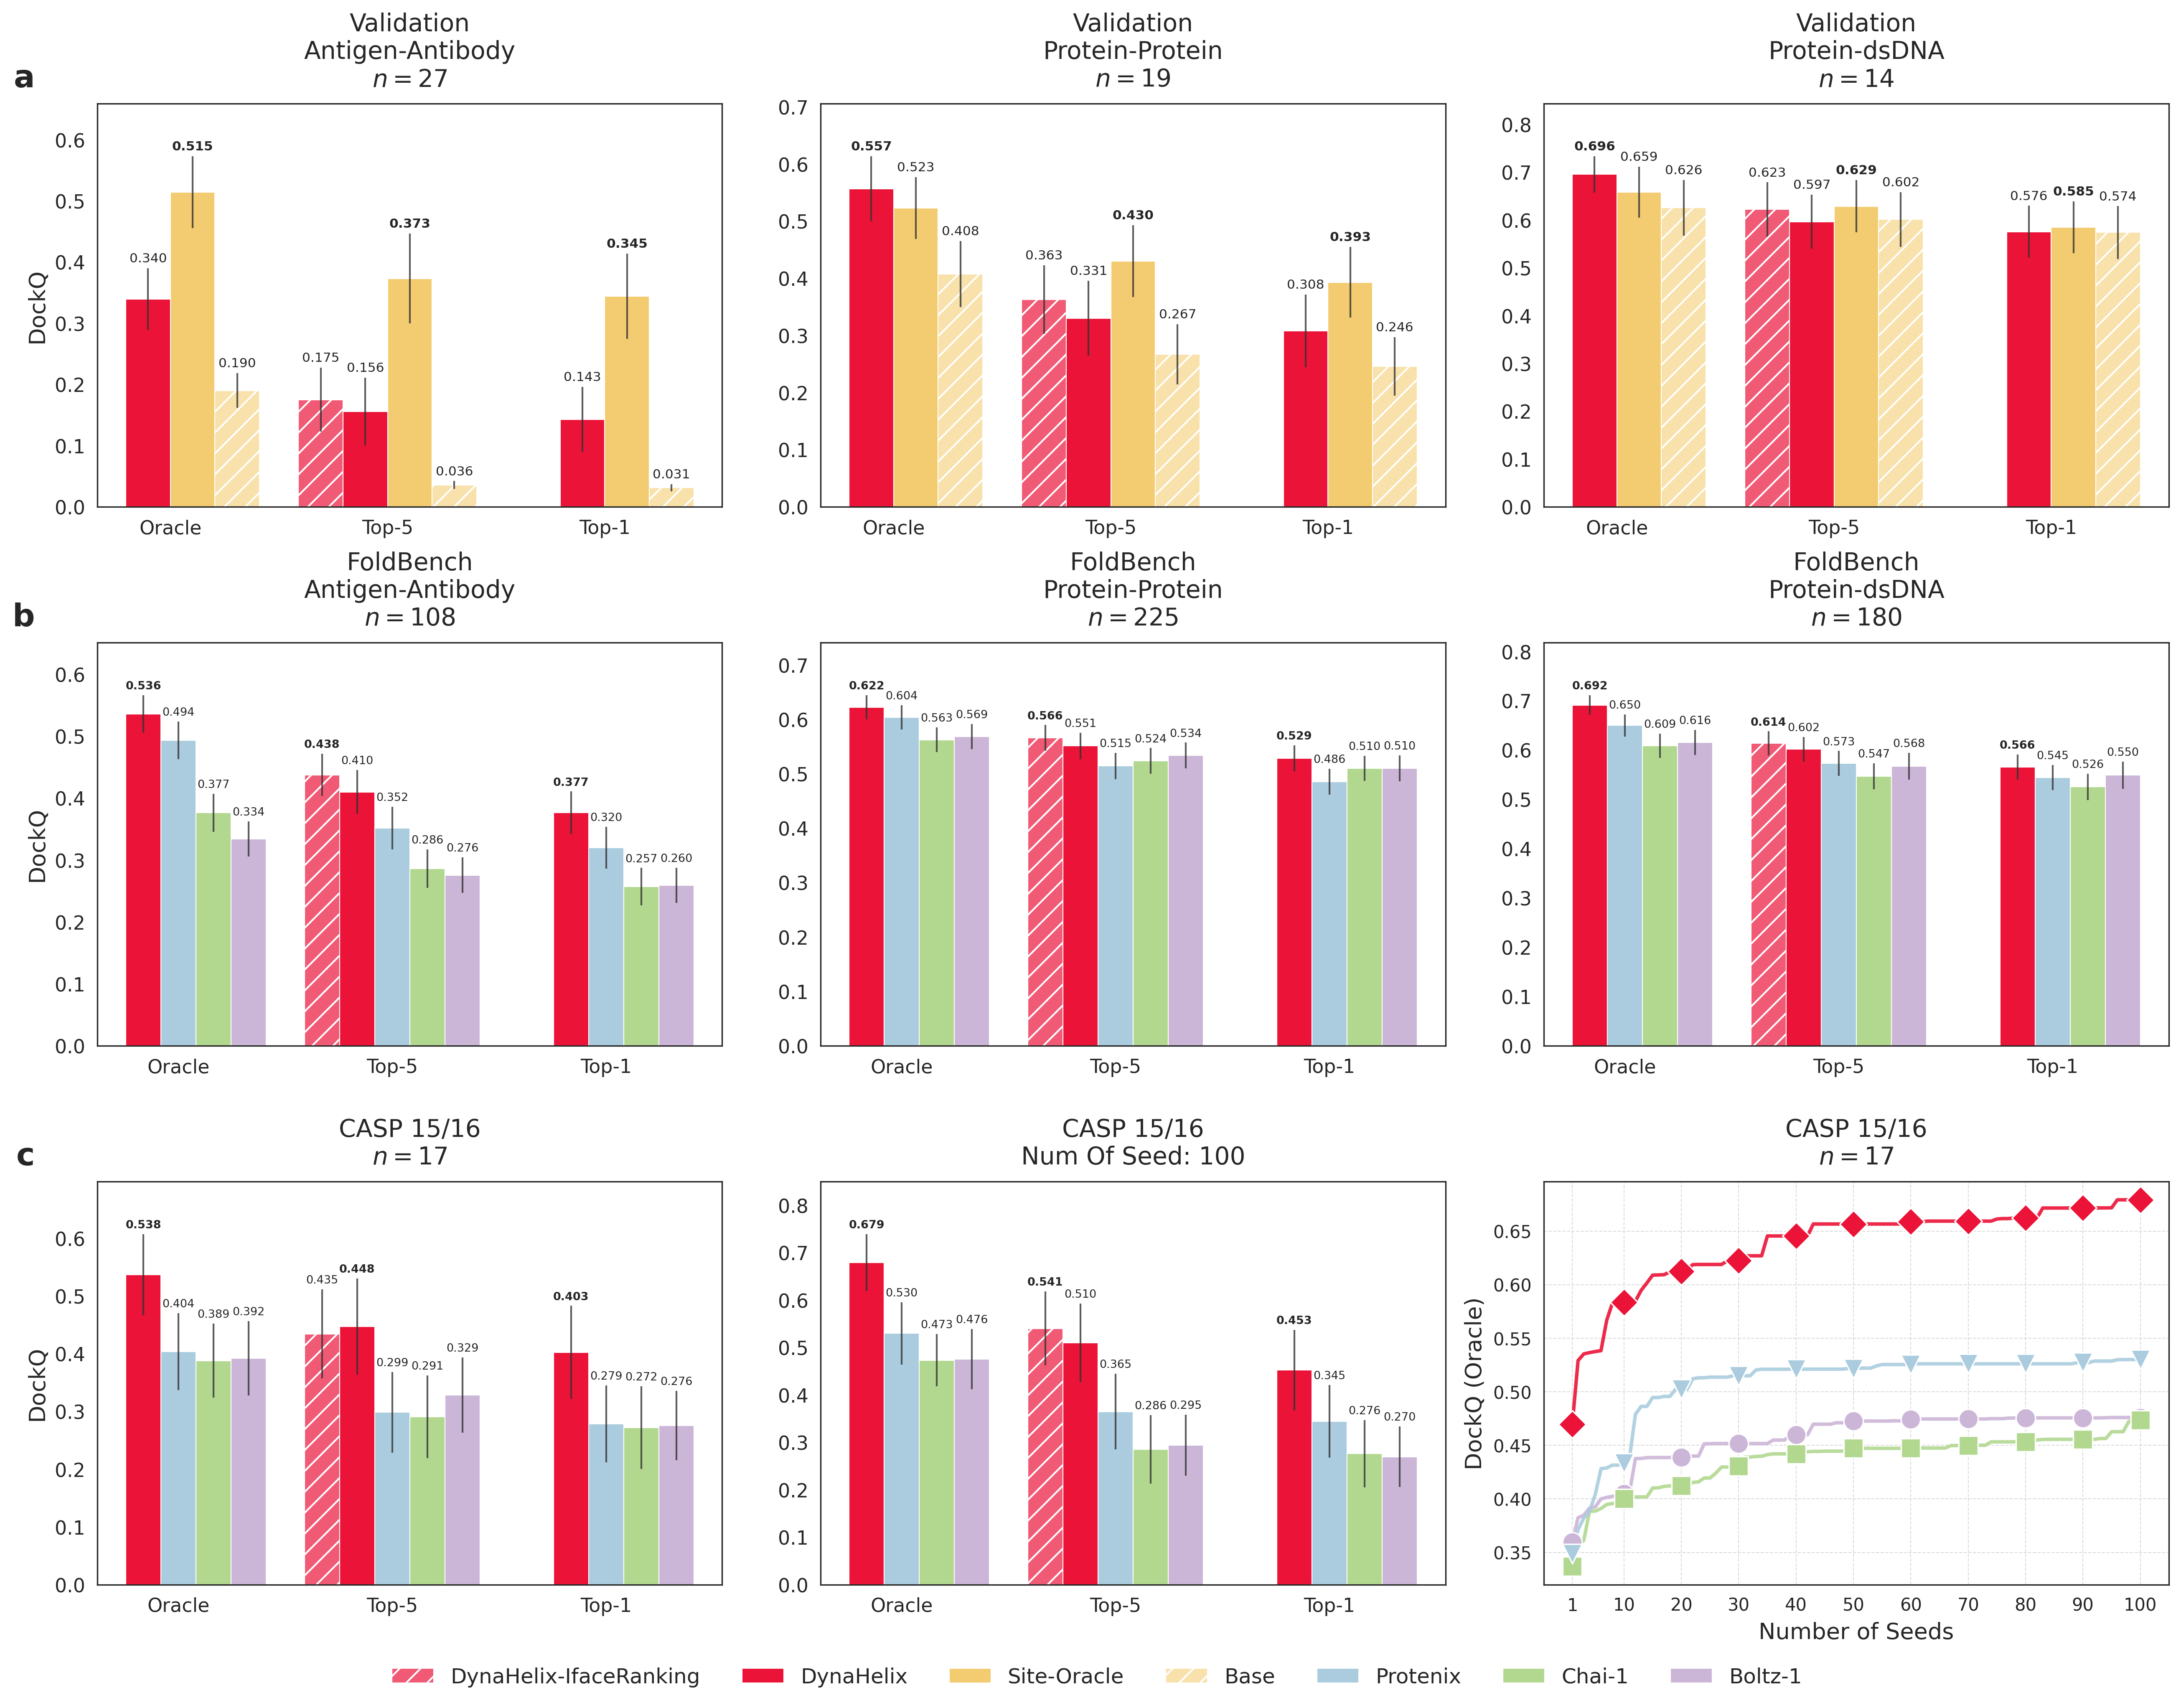

✅ 成功導出: ./figs/fig4.pdf

🚀 [2/4] 正在繪製第 2 圖 (Main iLDDT)...

--- [iLDDT] 各 Dataset 共有 PDB 數量統計 ---
Dataset: CASP 15/16                | Common PDB Count: 17
Dataset: CASP 15/16
Num Of Seed: 100 | Common PDB Count: 17
Dataset: fb_AA                     | Common PDB Count: 108
Dataset: fb_PP                     | Common PDB Count: 225
Dataset: fb_dsDNA                  | Common PDB Count: 180
Dataset: vali_AA                   | Common PDB Count: 27
Dataset: vali_PP                   | Common PDB Count: 19
Dataset: vali_dsDNA                | Common PDB Count: 14
--------------------------------------------------


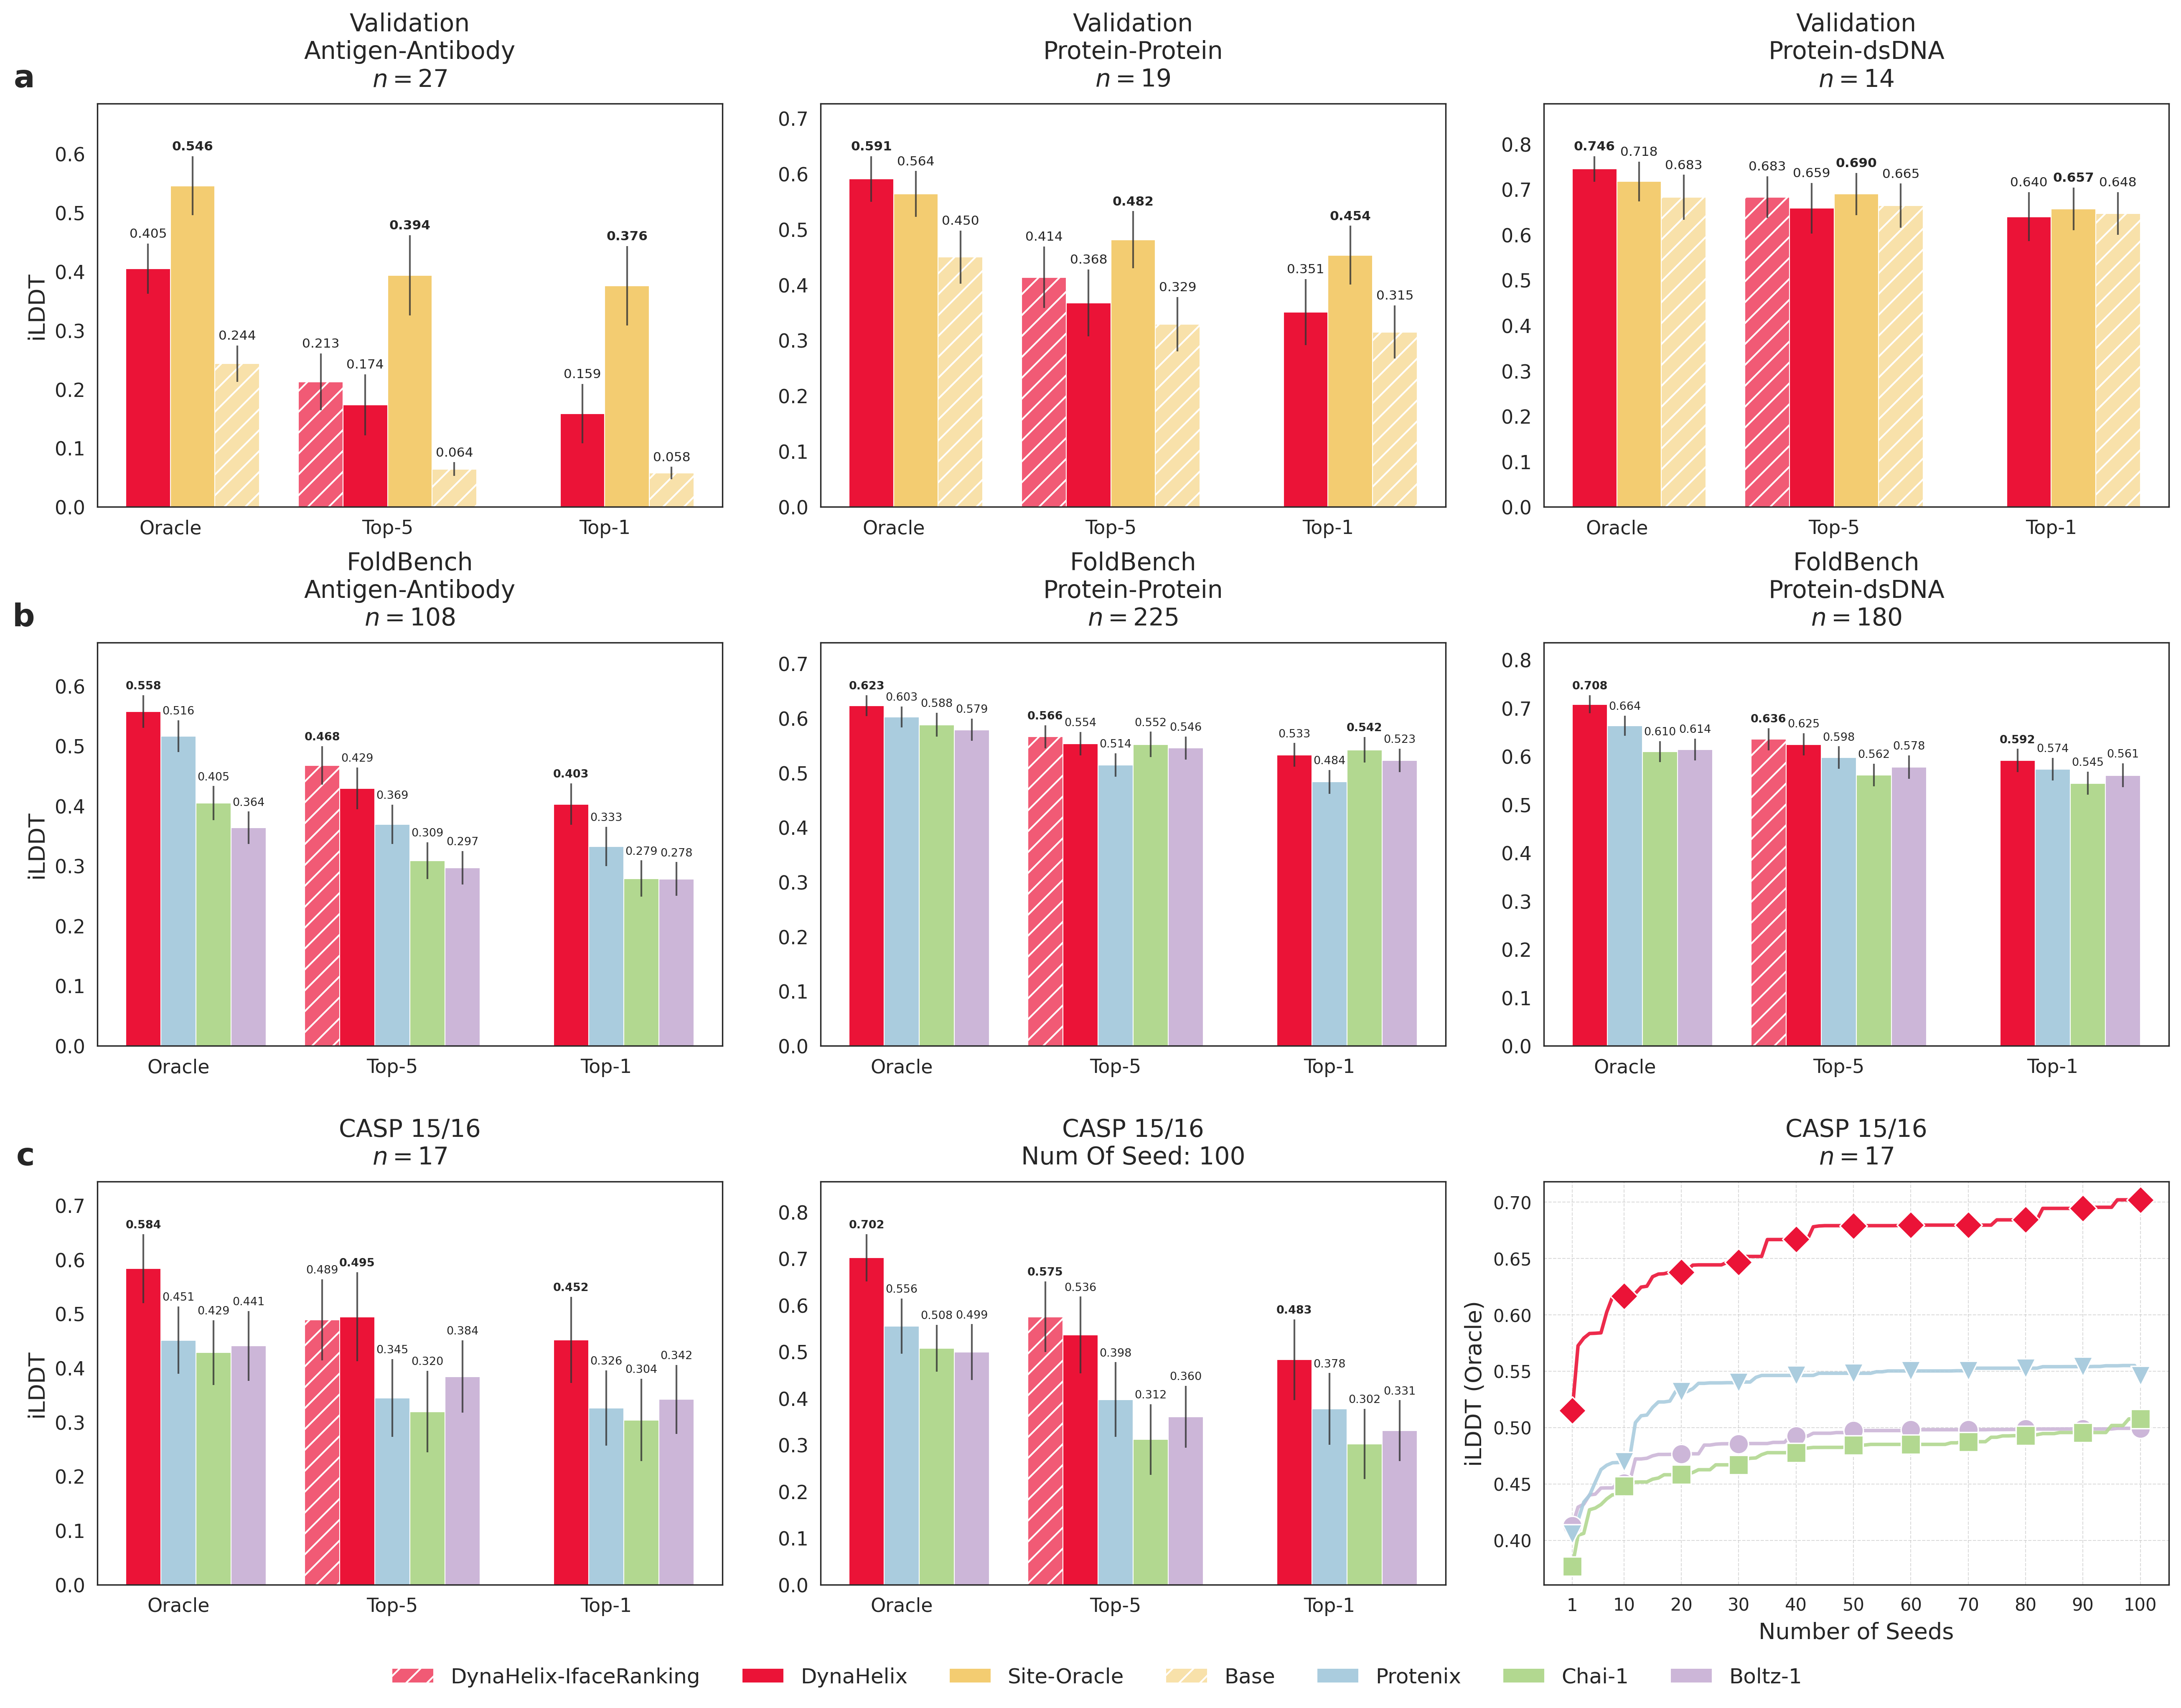

✅ 成功導出: ./figs/supple_ilddt.pdf

🚀 [3/4] 正在繪製第 3 圖 (Supplementary Chai-1)...

--- [DockQ] 各 Dataset 共有 PDB 數量統計 ---
Dataset: CASP 15/16                | Common PDB Count: 17
Dataset: CASP 15/16
Num Of Seed: 100 | Common PDB Count: 17
Dataset: fb_AA                     | Common PDB Count: 108
Dataset: fb_PP                     | Common PDB Count: 225
Dataset: fb_dsDNA                  | Common PDB Count: 180
Dataset: vali_AA                   | Common PDB Count: 27
Dataset: vali_PP                   | Common PDB Count: 19
Dataset: vali_dsDNA                | Common PDB Count: 14
--------------------------------------------------


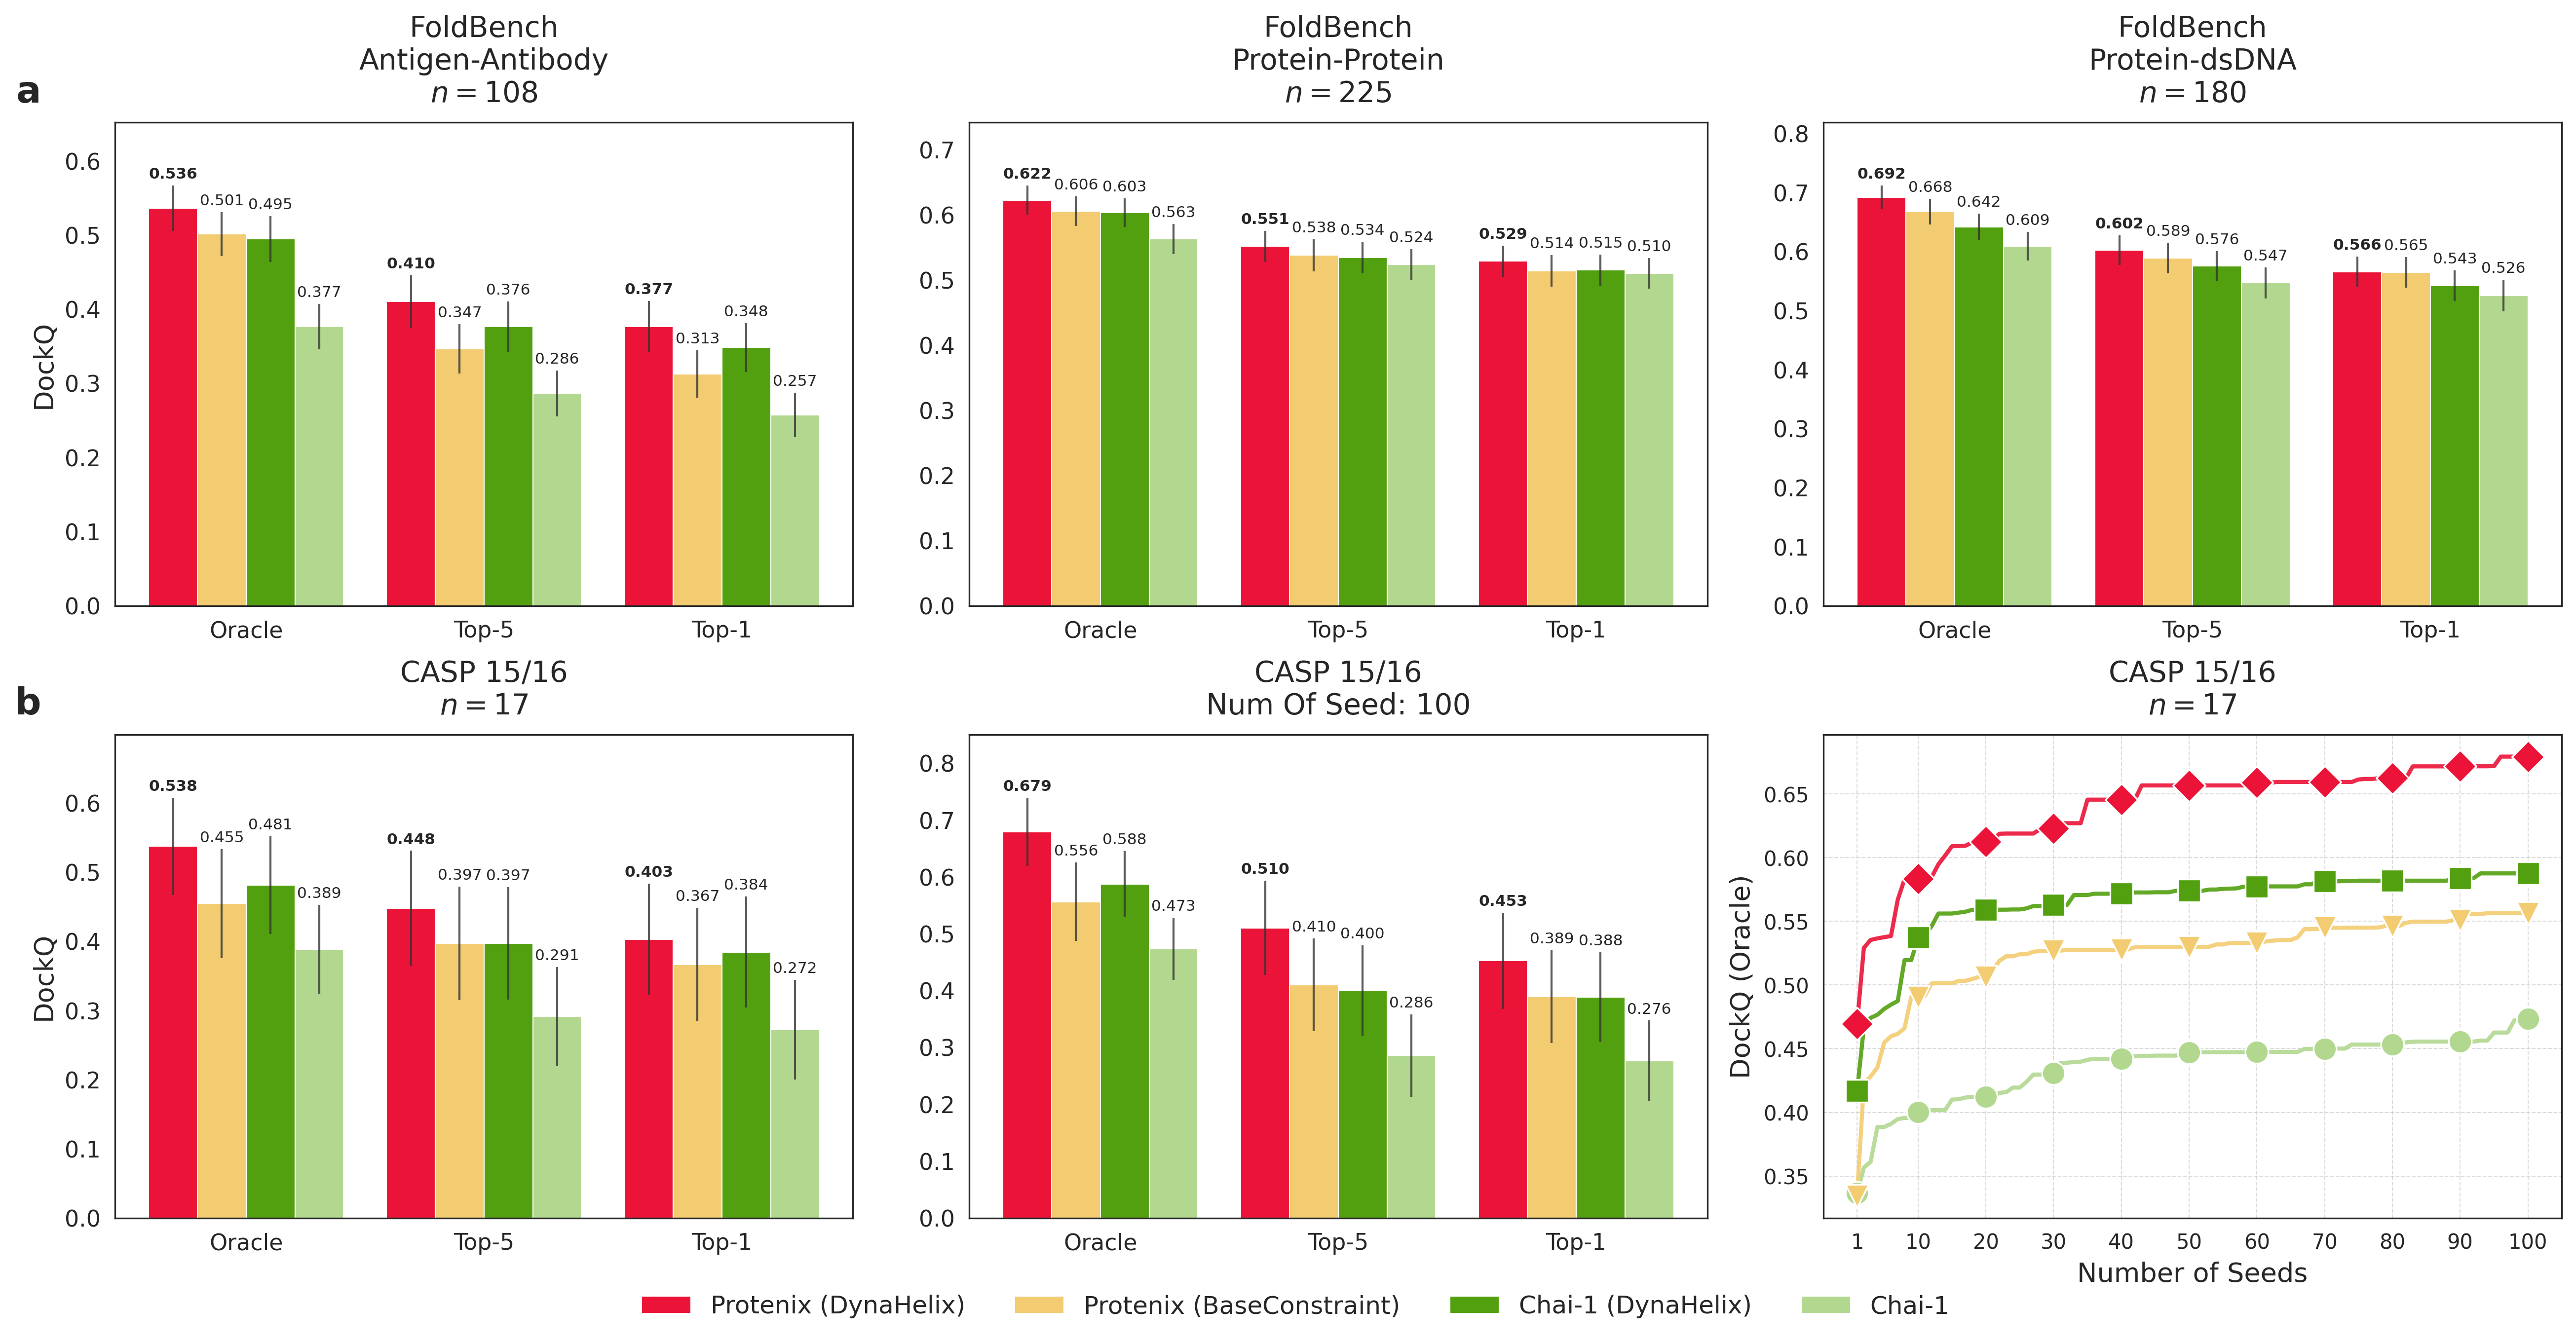

✅ 成功導出: ./figs/supple_chai1.pdf

🚀 [4/4] 正在繪製第 4 圖 (Supplementary Ablation)...


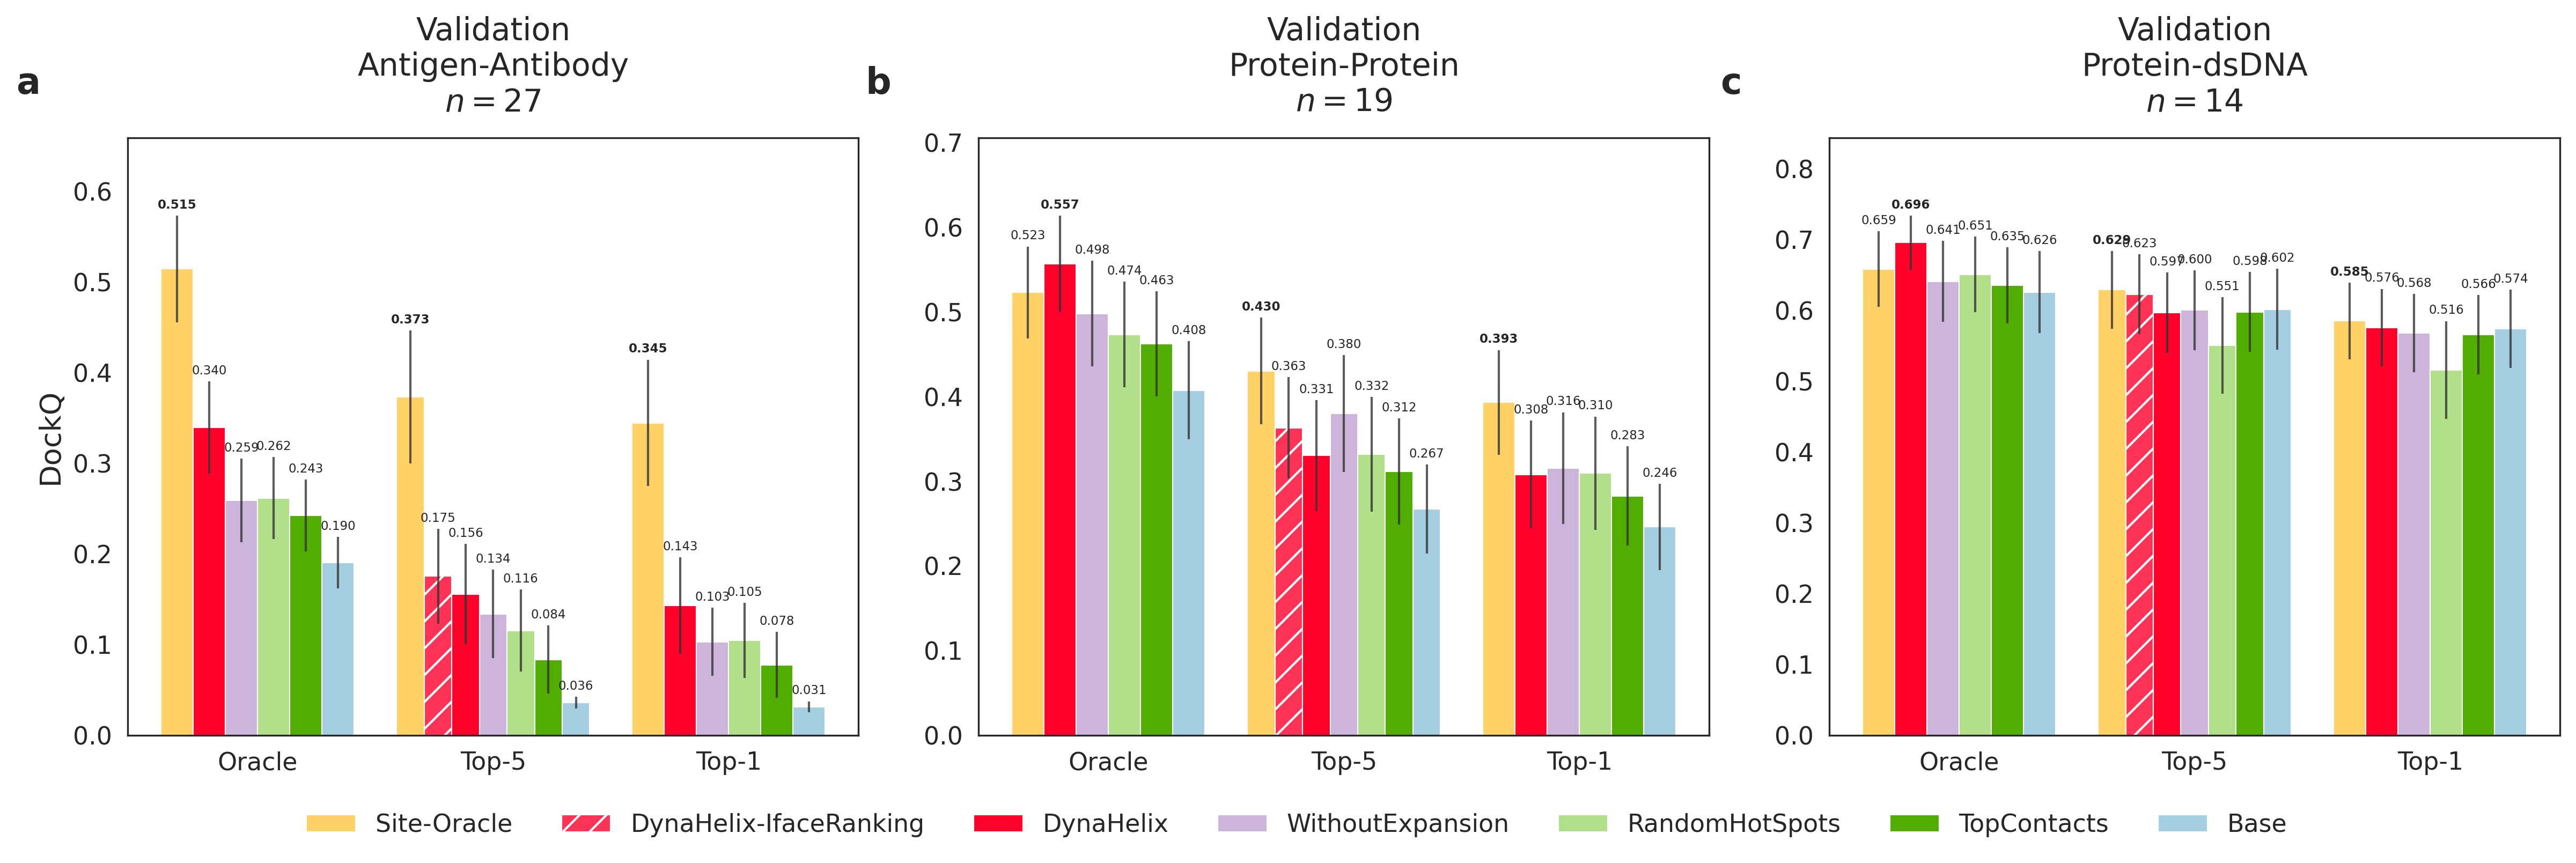

✅ 成功導出第 4 圖 (消融實驗): ./figs/supple_ablation.pdf

🎉 所有 4 張圖表均已成功繪製並導出完畢！


In [5]:
if "df" in locals():
    # ==========================================
    # 1. 第 1 圖: Main DockQ Grid (3x3 Layout)
    # ==========================================
    print("\n🚀 [1/4] 正在繪製第 1 圖 (Main DockQ)...")
    plot_df_dockq, counts_dockq = calculate_metrics(df, score_col="idockq", score_name="DockQ")

    draw_grid_barplot(
        plot_df=plot_df_dockq,
        dataset_pdb_counts=counts_dockq,
        raw_df=df,
        score_col="idockq",
        metric_name="DockQ",
        layout_grid=MAIN_GRID,
        master_hue_order=MAIN_METHODS_ORDER,
        save_path="./figs/fig4.pdf",
        line_plot_pos=(2, 2),
        selected_line_methods=["Boltz-1", "Chai-1", "DynaHelix", "Protenix", "Base"],
    )

    # ==========================================
    # 2. 第 2 圖: Main iLDDT Grid (3x3 Layout)
    # ==========================================
    print("\n🚀 [2/4] 正在繪製第 2 圖 (Main iLDDT)...")
    plot_df_ilddt, counts_ilddt = calculate_metrics(df, score_col="ilddt", score_name="iLDDT")

    plot_df = pd.concat([plot_df_dockq, plot_df_ilddt])
    plot_df.to_csv("./figs/score.summary.csv", index=False)

    draw_grid_barplot(
        plot_df=plot_df_ilddt,
        dataset_pdb_counts=counts_ilddt,
        raw_df=df,
        score_col="ilddt",
        metric_name="iLDDT",
        layout_grid=MAIN_GRID,
        master_hue_order=MAIN_METHODS_ORDER,
        save_path="./figs/supple_ilddt.pdf",
        line_plot_pos=(2, 2),
        selected_line_methods=["Boltz-1", "Chai-1", "DynaHelix", "Protenix", "Base"],
    )

    # ==========================================
    # 3. 第 3 圖: Supplementary Chai-1 (2x3 Layout) - 補齊調用！
    # ==========================================
    print("\n🚀 [3/4] 正在繪製第 3 圖 (Supplementary Chai-1)...")
    CHAI1_METHODS = [
        "Protenix (DynaHelix-IfaceRanking)",
        "Protenix (DynaHelix)",
        "Protenix (BaseConstraint)",
        "Chai-1 (DynaHelix)",
        "Chai-1",
    ]
    CHAI1_GRID = [
        ["fb_AA", "fb_PP", "fb_dsDNA"],
        ["CASP 15/16", "CASP 15/16\nNum Of Seed: 100", "CASP 15/16"],
    ]
    CHAI1_MAPPING = {
        "DynaHelix": "Protenix (DynaHelix)",
        "DynaHelix-IfaceRanking": "Protenix (DynaHelix-IfaceRanking)",
        "Base": "Protenix (BaseConstraint)",
    }

    plot_df_chai1, counts_chai1 = calculate_metrics(
        df, score_col="idockq", score_name="DockQ", method_mapping=CHAI1_MAPPING
    )

    draw_grid_barplot(
        plot_df=plot_df_chai1,
        dataset_pdb_counts=counts_chai1,
        raw_df=df,
        score_col="idockq",
        metric_name="DockQ",
        layout_grid=CHAI1_GRID,
        master_hue_order=CHAI1_METHODS,
        method_mapping=CHAI1_MAPPING,
        save_path="./figs/supple_chai1.pdf",
        line_plot_pos=(1, 2),
        selected_line_methods=[
            "Chai-1",
            "Chai-1 (DynaHelix)",
            "Protenix (DynaHelix)",
            "Protenix (BaseConstraint)",
        ],
    )

    # ==========================================
    # 4. 第 4 圖: Supplementary Ablation Study (1x3 Layout)
    # ==========================================
    print("\n🚀 [4/4] 正在繪製第 4 圖 (Supplementary Ablation)...")
    draw_ablation_barplot(plot_df_dockq, counts_map=counts_dockq)

    print("\n🎉 所有 4 張圖表均已成功繪製並導出完畢！")

else:
    print("⚠️ 找不到 `df` 變量，請確認 DataFrame 已經正確加載。")